In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy import signal

Cortesia de Thomas Andrade


In [1]:
def matrixCreator(raw, pixelsX, pixelsY):
    matrix = []
    for i in range(0, len(raw), pixelsX*pixelsY):
        blank = np.zeros((pixelsX, pixelsY))
        for j in range(0, pixelsX):
            for k in range(0, pixelsY):
                blank[j, k] = raw[k + pixelsX*j + i]
        matrix.append(blank) 
    return matrix

def dataCreator(filename, pixelsX, pixelsY):
    raw_array = np.fromfile(filename, dtype = "float32")
    matrix = matrixCreator(raw_array, pixelsX, pixelsY)
    return matrix

def imageCreator(data, COLValue):
    image = []
    mean = 0
    for i in range(0, COLValue + 1):
        mean += data[i]
    mean = mean/(COLValue + 1)
    image.append(mean)  
    return image[0]

In [ ]:
directory = "Resultados/Wax-Alumina.raw" # String con el directorio donde se encuentra el .raw.
COL = 0 # Cambiar por el tipo de adquisición.
pixelsX = 256 
pixelsY = 256

In [ ]:
sample = dataCreator(directory, pixelsX, pixelsY)
image = imageCreator(sample, COL)
plt.imshow(image, cmap='gray')

FLAT FIELD

In [ ]:
ffsample = dataCreator("Resultados/Flat_Field.raw", pixelsX, pixelsY)
ffimage = imageCreator(ffsample, COL)
plt.imshow(ffimage, cmap='gray')

___

Retrieval algoritm

<hr style="border: none; border-top: 2px dotted #808080; height: 0;">

A. Single-Mask DPC Configuration

Atenuation and DPC 

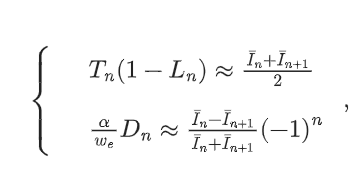 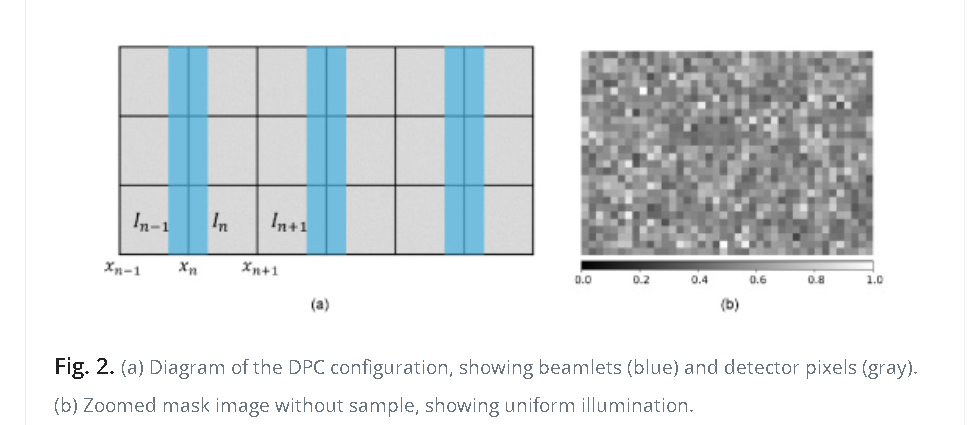

Dark Field


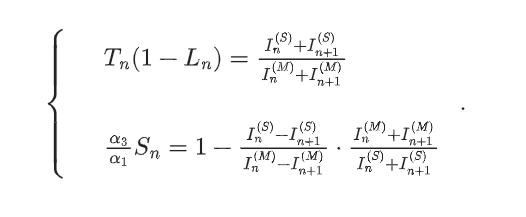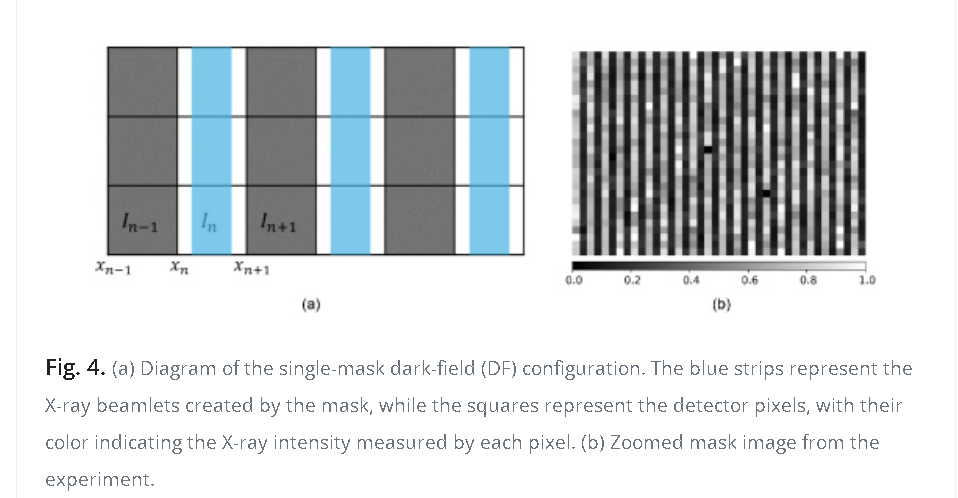

<hr style="border: none; border-top: 2px dotted #808080; height: 0;">

B. Single-Mask DF-DPC Configuration

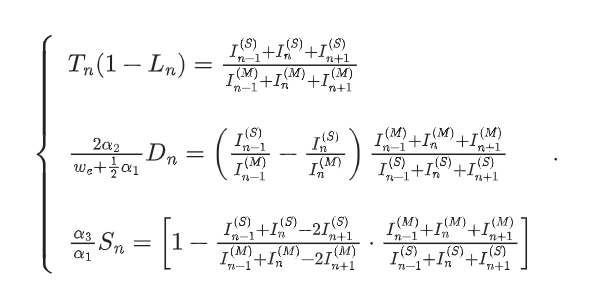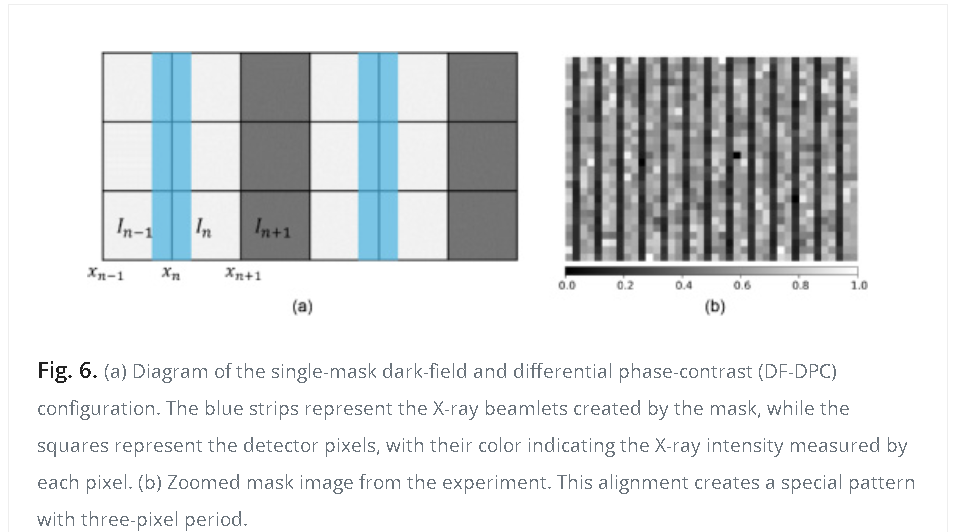

---

Resultados

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(12, 4), constrained_layout=True)

imagenes = [imagen_attenuacion, phase_grad, phase, dark_field]
titulos = ["Atenuación", "Diferencial de fase", "Fase", "Dark Field"]

for ax, img, titulo in zip(axes, imagenes, titulos):
    ax.imshow(img, cmap="gray")
    ax.set_title(titulo)
    ax.axis("off")
    ax.set_aspect("equal", adjustable="box")

plt.show()